In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

DATA = Path.cwd() / 'data'

In [2]:
df_client = pd.read_csv(DATA / 'client.asc', sep=';', na_values=[' ', '', 'NA', 'NULL', 'NaN'])

In [3]:
df_account = pd.read_csv(DATA / 'account.asc', sep=';', na_values=[' ', '', 'NA', 'NULL', 'NaN'])

In [4]:
df_client.head(5)

,client_id,birth_number,district_id
0,1,706213,18
1,2,450204,1
2,3,406009,1
3,4,561201,5
4,5,605703,5


In [5]:
df_account.head()

,account_id,district_id,frequency,date
0,576,55,POPLATEK MESICNE,930101
1,3818,74,POPLATEK MESICNE,930101
2,704,55,POPLATEK MESICNE,930101
3,2378,16,POPLATEK MESICNE,930101
4,2632,24,POPLATEK MESICNE,930102


In [6]:
df_client.dtypes

client_id       int64
birth_number    int64
district_id     int64
dtype: object

In [7]:
df_account.dtypes

account_id      int64
district_id     int64
frequency      object
date            int64
dtype: object

In [8]:
df_client["client_id"] = df_client["client_id"].astype('object')

In [9]:
df_client.dtypes

client_id       object
birth_number     int64
district_id      int64
dtype: object

In [10]:
df_client.describe(include = 'all')

,client_id,birth_number,district_id
count,5369.0,5369.000000,5369.000000
unique,5369.0,NaN,NaN
top,1.0,NaN,NaN
freq,1.0,NaN,NaN
mean,NaN,535114.970013,37.310114
std,NaN,172895.618429,25.043690
min,NaN,110820.000000,1.000000
25%,NaN,406009.000000,14.000000
50%,NaN,540829.000000,38.000000
75%,NaN,681013.000000,60.000000


In [11]:
df_account.describe()

,account_id,district_id,date
count,4500.000000,4500.000000,4500.000000
mean,2786.067556,37.310444,951654.608667
std,2313.811984,25.177217,14842.188377
min,1.000000,1.000000,930101.000000
25%,1182.750000,13.000000,931227.000000
50%,2368.000000,38.000000,960102.000000
75%,3552.250000,60.000000,961101.000000
max,11382.000000,77.000000,971229.000000


<Axes: >

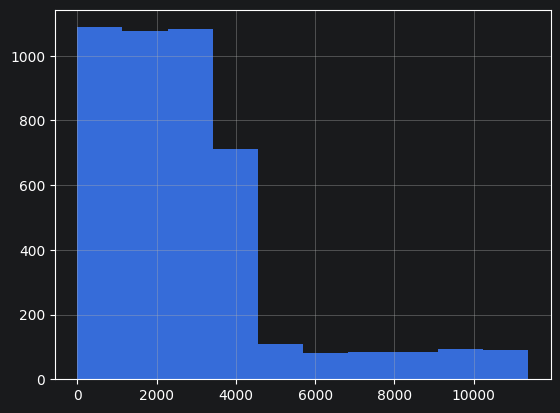

In [12]:
df_account['account_id'].hist()

No importa que paresca número se debe convertir en object
La columna account_id es un valor unico o compartido por algunas instancias

In [13]:
df_account["account_id"] = df_account["account_id"].astype('object')

In [14]:
df_account = df_account.astype({'account_id':'object', 'district_id':'object'})

In [15]:
df_account.dtypes

account_id     object
district_id    object
frequency      object
date            int64
dtype: object

In [16]:
df_client.describe(include = 'all')

,client_id,birth_number,district_id
count,5369.0,5369.000000,5369.000000
unique,5369.0,NaN,NaN
top,1.0,NaN,NaN
freq,1.0,NaN,NaN
mean,NaN,535114.970013,37.310114
std,NaN,172895.618429,25.043690
min,NaN,110820.000000,1.000000
25%,NaN,406009.000000,14.000000
50%,NaN,540829.000000,38.000000
75%,NaN,681013.000000,60.000000


In [17]:
df_account.describe(include = 'all')

,account_id,district_id,frequency,date
count,4500.0,4500.0,4500,4500.000000
unique,4500.0,77.0,3,NaN
top,576.0,1.0,POPLATEK MESICNE,NaN
freq,1.0,554.0,4167,NaN
mean,NaN,NaN,NaN,951654.608667
std,NaN,NaN,NaN,14842.188377
min,NaN,NaN,NaN,930101.000000
25%,NaN,NaN,NaN,931227.000000
50%,NaN,NaN,NaN,960102.000000
75%,NaN,NaN,NaN,961101.000000


In [18]:
df_account.columns

Index(['account_id', 'district_id', 'frequency', 'date'], dtype='object')

In [19]:
df_account.sample(4).head(4).T

,55,296,3580,4429
account_id,2330,2245,2761,934
district_id,54,29,1,9
frequency,POPLATEK MESICNE,POPLATEK MESICNE,POPLATEK MESICNE,POPLATEK MESICNE
date,930119,930330,961226,971127


In [20]:
df_account.head()

,account_id,district_id,frequency,date
0,576,55,POPLATEK MESICNE,930101
1,3818,74,POPLATEK MESICNE,930101
2,704,55,POPLATEK MESICNE,930101
3,2378,16,POPLATEK MESICNE,930101
4,2632,24,POPLATEK MESICNE,930102


In [21]:
### Analisis bivariado respecto de la variable objetivo

In [22]:
df_disp = pd.read_csv(DATA / 'disp.asc', sep=';', na_values=[' ', '', 'NA', 'NULL', 'NaN'])
df_loan = pd.read_csv(DATA / 'loan.asc', sep=';', na_values=[' ', '', 'NA', 'NULL', 'NaN'])

df_account_loan = pd.merge(df_account, df_loan, on='account_id', how='inner')

df_account_loan.groupby(['status']).agg({
    'amount':'mean', 
    'duration':'mean', 
    'payments':'mean'
}).sort_values(['status'], ascending = True)

,amount,duration,payments
status,,,
A,91641.458128,22.226601,4264.137931
B,140720.903226,25.548387,5396.258065
C,171410.352357,43.444169,3938.535980
D,249284.533333,46.133333,5286.644444


In [23]:
df_disp_owner = df_disp[df_disp['type'] == 'OWNER']
df_berka = pd.merge(df_client, df_disp_owner, on='client_id')
df_berka = pd.merge(df_berka, df_account, on='account_id', suffixes=('_client', '_account'))
df_berka = pd.merge(df_berka, df_loan[['account_id', 'amount', 'duration', 'payments', 'status']], on='account_id', how='left')
df_berka['target'] = df_berka['status'].map({'A': 1, 'C': 1, 'B': 0, 'D': 0})

df_berka.head(1).T

,0
client_id,1
birth_number,706213
district_id_client,18
disp_id,1
account_id,1
type,OWNER
district_id_account,18
frequency,POPLATEK MESICNE
date,950324
amount,NaN


In [24]:
df_berka.groupby(['target']).agg({'amount':'mean', 'payments':'mean'}).sort_values(['target'], ascending = True)

,amount,payments
target,,
0.0,205002.000000,5331.355263
1.0,144689.089109,4047.607261


## Analisis bivariado entre variables categóricas

In [25]:
df_berka.groupby(['frequency','target'], dropna=False).agg({'amount':'mean'})

amount
frequency          target               
POPLATEK MESICNE   0.0     210890.440678
                   1.0     139723.488000
                   NaN               NaN
POPLATEK PO OBRATU 0.0     135040.000000
                   1.0     171462.461538
                   NaN               NaN
POPLATEK TYDNE     0.0     211579.636364
                   1.0     167022.750000
                   NaN               NaN

In [26]:
df_berka.groupby(['frequency','status'], dropna=False).agg({'amount':'mean'})

amount
frequency          status               
POPLATEK MESICNE   A        87465.428571
                   B       132923.454545
                   C       166167.325301
                   D       257249.189189
                   NaN               NaN
POPLATEK PO OBRATU A       116614.500000
                   B        95260.000000
                   C       195839.333333
                   D       174820.000000
                   NaN               NaN
POPLATEK TYDNE     A       110226.222222
                   B       192042.000000
                   C       195956.830189
                   D       235024.800000
                   NaN               NaN

In [27]:
df_berka.groupby(['type','target'], dropna=False).agg({'amount':'mean'})

amount
type  target               
OWNER 0.0     205002.000000
      1.0     144689.089109
      NaN               NaN